In [24]:
from langgraph.graph import StateGraph, START,END
from langchain_google_genai import ChatGoogleGenerativeAI
from typing import TypedDict
from dotenv import load_dotenv

In [25]:
class BatsmanState(TypedDict):
    runs:int
    balls:int
    fours:int
    sixes:int
    sr:float
    bpb:float
    boundary_perc:float
    Summary:str

In [26]:
def calculate_sr(state:BatsmanState)->BatsmanState:
    runs=state['runs']
    balls=state['balls']
    state['sr']=(runs/balls) * 100
    return {"sr": state['sr']}

def calculate_bpb(state:BatsmanState)->BatsmanState:
    fours=state['fours']
    sixes=state['sixes']
    balls=state['balls']
    state['bpb']=(fours + sixes )/balls
    return {"bpb":state['bpb']}

def calculate_boundary_perc(state:BatsmanState)->BatsmanState:
    boundaries=(state['fours'] * 4 )+ (state['sixes'] * 6)
    state['boundary_perc']= (boundaries / state['runs']) * 100
    return {"boundary_perc":state['boundary_perc']}

def Summary(state:BatsmanState) -> BatsmanState:
    state['Summary']= f"""
        Strike Rate: {state['sr']}
        Boundaries Per Ball : {state['bpb']}
        Boundaries Percentage: {state['boundary_perc']}
        """
    return state

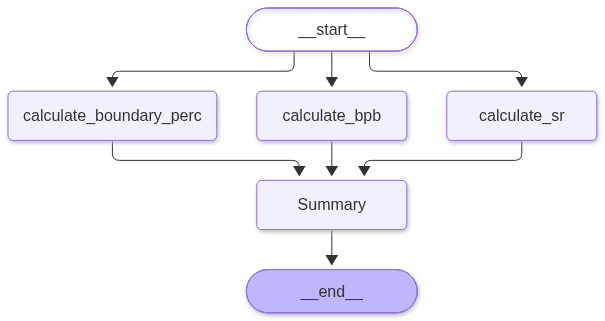

In [27]:
graph=StateGraph(BatsmanState)
graph.add_node('calculate_sr',calculate_sr)
graph.add_node('calculate_bpb',calculate_bpb)
graph.add_node('calculate_boundary_perc',calculate_boundary_perc)
graph.add_node('Summary',Summary)

graph.add_edge(START,'calculate_sr')
graph.add_edge(START,'calculate_bpb')
graph.add_edge(START,'calculate_boundary_perc')
graph.add_edge('calculate_sr','Summary')
graph.add_edge('calculate_bpb',"Summary")
graph.add_edge('calculate_boundary_perc', 'Summary')
graph.add_edge('Summary', END)

workflow = graph.compile()
workflow

In [28]:
initial_state={
    'runs' :106,
    'balls':105,
    'fours':11,
    'sixes':4,

}
output_state=workflow.invoke(initial_state)
output_state

{'runs': 106,
 'balls': 105,
 'fours': 11,
 'sixes': 4,
 'sr': 100.95238095238095,
 'bpb': 0.14285714285714285,
 'boundary_perc': 64.15094339622641,
 'Summary': '\n        Strike Rate: 100.95238095238095\n        Boundaries Per Ball : 0.14285714285714285\n        Boundaries Percentage: 64.15094339622641\n        '}